In [2]:
# ===== SETUP: libraries, names and small helper functions =====
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)

try:
    from IPython.display import display
except ImportError:          # only used if you run this as a plain .py file
    display = print

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# ---- CHANGE THESE ----
LAST_NAME    = "Baclay"
FIRST_NAME   = "ChristJohn"
STUDENT_NAME = "Baclay, Christ John S."     # shown on the report
SECTION      = "BSIS 3B"
# -----------------------
FILE_STEM    = f"SectionB_{LAST_NAME}_{FIRST_NAME}_ExamV2"
CSV_PATH     = "student_service_requests.csv"
CLEAN_CSV    = f"{FILE_STEM}.csv"
UML_PNG      = f"{FILE_STEM}_UML.png"
REPORT_PDF   = f"{FILE_STEM}.pdf"
RANDOM_STATE = 42

# If the CSV is not in the folder, ask for an upload (works in Google Colab)
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        CSV_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Put {CSV_PATH} in the same folder as this notebook.")

# Things we collect here are printed again in the final PDF report
REPORT = []
def rep_h(text):                 REPORT.append(("h", text))
def rep_p(text):                 REPORT.append(("p", text))
def rep_table(frame, caption=""): REPORT.append(("t", frame.copy(), caption))
def rep_img(path, caption=""):   REPORT.append(("i", path, caption))

def pct(x):
    return f"{x * 100:.1f}%"

print("Setup done. Data file:", CSV_PATH)

Setup done. Data file: student_service_requests.csv


---
# Part I - Dataset Loading and Understanding
## Question 1 - Load the CSV, preview, shape, data types and category counts

In [3]:
raw = pd.read_csv(CSV_PATH)

print("Shape (rows, columns):", raw.shape)
print("\nFirst 10 rows:")
display(raw.head(10))

print("\nData types:")
print(raw.dtypes)

# Category frequencies for every text column (ID and date are skipped)
text_columns = [c for c in raw.columns
                if not pd.api.types.is_numeric_dtype(raw[c])
                and c not in ("Request_ID", "Submission_Date")]
for col in text_columns:
    print(f"\n--- {col} ---")
    print(raw[col].value_counts(dropna=False))

# Does the file match the schema in the exam paper?
expected_cols = ["Request_ID", "Service_Type", "Requester_Type", "Submission_Date",
                 "Requested_Channel", "Priority", "Assigned_Office", "Queue_Length",
                 "Required_Documents_Complete", "Processing_Days", "SLA_Days",
                 "Status", "Reopened", "Satisfaction_Score"]
print("\nColumns expected but NOT found:", [c for c in expected_cols if c not in raw.columns] or "none")
print("Extra columns found:", [c for c in raw.columns if c not in expected_cols] or "none")

rep_h("Part I - Dataset understanding")
rep_p(f"The file has {raw.shape[0]} rows and {raw.shape[1]} columns "
      f"({raw['Request_ID'].nunique()} different Request_ID values).")

Shape (rows, columns): (403, 14)

First 10 rows:


,Request_ID,Service_Type,Requester_Type,Submission_Date,Requested_Channel,Priority,Assigned_Office,Queue_Length,Required_Documents_Complete,Processing_Days,SLA_Days,Status,Reopened,Satisfaction_Score
0,REQ1000,Records,Faculty,2024-06-12,Walk-in,Low,Dean's Office,8.0,Yes,9.3,5,Completed,No,1.0
1,REQ1001,IT Support,Student,2024-01-29,Portal,Normal,Dean's Office,9.0,Yes,5.6,2,Completed,Yes,4.0
2,REQ1002,IT Support,Faculty,2024-01-07,Email,Low,Scholarship Office,19.0,Yes,9.7,2,Completed,Yes,3.0
3,REQ1003,Records,Student,2024-03-11,Portal,Normal,Registrar,6.0,No,9.8,5,Completed,No,2.0
4,REQ1004,Records,Staff,2024-03-03,Portal,High,IT Office,22.0,Yes,9.6,5,Completed,No,2.0
5,REQ1005,Enrollment,Faculty,2024-02-27,Walk-in,Normal,Dean's Office,10.0,Yes,9.4,4,Completed,Yes,5.0
6,REQ1006,Enrollment,Student,2024-02-05,Walk-in,High,Dean's Office,6.0,No,8.5,4,Completed,No,2.0
7,REQ1007,Enrollment,Faculty,2024-01-27,Email,High,Registrar,21.0,Yes,NaN,4,Pending,NaN,NaN
8,REQ1008,Scholarship Inquiry,Student,2024-06-22,Email,Low,IT Office,20.0,Yes,13.6,7,Completed,No,4.0
9,REQ1009,Scholarship Inquiry,Staff,2024-05-19,Email,Normal,Scholarship Office,8.0,Yes,7.5,7,Completed,No,1.0



Data types:
Request_ID                      object
Service_Type                    object
Requester_Type                  object
Submission_Date                 object
Requested_Channel               object
Priority                        object
Assigned_Office                 object
Queue_Length                   float64
Required_Documents_Complete     object
Processing_Days                float64
SLA_Days                         int64
Status                          object
Reopened                        object
Satisfaction_Score             float64
dtype: object

--- Service_Type ---
Service_Type
IT Support             88
Enrollment             80
Records                78
Scholarship Inquiry    72
Certification          72
Schol.                  7
ITSupp                  4
Cert.                   1
Rec.                    1
Name: count, dtype: int64

--- Requester_Type ---
Requester_Type
Staff      166
Student    124
Faculty    113
Name: count, dtype: int64

--- Requested_Channel

## Question 2 - Predictors, target, variable types and identifier (compact data dictionary)

In [4]:
data_dictionary = pd.DataFrame([
    ["Request_ID",                  "Identifier",                 "Text",   "Unique number of a request. Only used to find a record, never to predict."],
    ["Service_Type",                "Predictor (categorical)",    "Text",   "Kind of service asked for. Known at submission."],
    ["Requester_Type",              "Predictor (categorical)",    "Text",   "Student, Faculty or Staff. Known at submission."],
    ["Submission_Date",             "Source of a new feature",    "Date",   "Day the request was sent. Used to make Submission_Weekday."],
    ["Requested_Channel",           "Predictor (categorical)",    "Text",   "Portal, Email or Walk-in. Known at submission."],
    ["Priority",                    "Predictor (categorical)",    "Text",   "Low, Normal or High. Known at submission."],
    ["Assigned_Office",             "Predictor (categorical)",    "Text",   "Office that handles the request. Assumed to be set when the request is sent."],
    ["Queue_Length",                "Predictor (numerical)",      "Number", "Open requests at the time of submission."],
    ["Required_Documents_Complete", "Predictor (categorical)",    "Yes/No", "Were all papers given? Known at submission."],
    ["SLA_Days",                    "Predictor (numerical)",      "Number", "Target days allowed. Set when the request is sent."],
    ["Processing_Days",             "NOT allowed as predictor",   "Number", "Real days to finish. Only known later. Used only to build the target."],
    ["Status",                      "NOT allowed as predictor",   "Text",   "Completed, Pending or Cancelled. Known only after work. Used to pick labeled rows."],
    ["Reopened",                    "NOT allowed as predictor",   "Yes/No", "Known only after completion."],
    ["Satisfaction_Score",          "NOT allowed as predictor",   "Number", "Rating after service. Known only after completion."],
    ["Submission_Weekday",          "Predictor (created)",        "Text",   "Day name made from Submission_Date."],
    ["Queue_Category",              "Created (for analysis)",     "Text",   "Low 0-5, Medium 6-15, High >15, from Queue_Length."],
    ["SLA_Breached",                "TARGET (created)",           "0 / 1",  "1 if Processing_Days > SLA_Days, else 0. Only for completed requests."],
], columns=["Field", "Role", "Type", "Meaning / note"])
display(data_dictionary)

print("Five plausible predictors : Service_Type, Priority, Assigned_Office, Queue_Length, Required_Documents_Complete")
print("Target variable           : SLA_Breached")
print("Two categorical variables : Service_Type, Priority")
print("Two numerical variables   : Queue_Length, SLA_Days")
print("One identifier            : Request_ID")

rep_table(data_dictionary, "Data dictionary")

,Field,Role,Type,Meaning / note
0,Request_ID,Identifier,Text,Unique number of a request. Only used to find ...
1,Service_Type,Predictor (categorical),Text,Kind of service asked for. Known at submission.
2,Requester_Type,Predictor (categorical),Text,"Student, Faculty or Staff. Known at submission."
3,Submission_Date,Source of a new feature,Date,Day the request was sent. Used to make Submiss...
4,Requested_Channel,Predictor (categorical),Text,"Portal, Email or Walk-in. Known at submission."
5,Priority,Predictor (categorical),Text,"Low, Normal or High. Known at submission."
6,Assigned_Office,Predictor (categorical),Text,Office that handles the request. Assumed to be...
7,Queue_Length,Predictor (numerical),Number,Open requests at the time of submission.
8,Required_Documents_Complete,Predictor (categorical),Yes/No,Were all papers given? Known at submission.
9,SLA_Days,Predictor (numerical),Number,Target days allowed. Set when the request is s...


Five plausible predictors : Service_Type, Priority, Assigned_Office, Queue_Length, Required_Documents_Complete
Target variable           : SLA_Breached
Two categorical variables : Service_Type, Priority
Two numerical variables   : Queue_Length, SLA_Days
One identifier            : Request_ID


## Question 3 - How can this dataset be collected from an online portal?
**Using an API:** The portal can offer a REST API (for example `/api/service-requests`). A Python script sends an HTTPS request with a login token and a date range, reads the answer as JSON, goes through all pages, and puts the rows into a Pandas DataFrame. A scheduled job (for example every night) can ask only for new requests.

**Using a database connection:** If the portal saves data in a database (MySQL, PostgreSQL, etc.), a read-only user can connect with SQLAlchemy and run a `SELECT` query. `pd.read_sql` returns the result as a DataFrame. Names of people should not be selected, only the fields in the data dictionary. A read-only account keeps the live system safe.

The two functions below show the idea. They are **examples and are not run**, because we do not have the real portal address.

In [5]:
# EXAMPLE ONLY - not executed (we do not have the real portal address or password)
def load_from_api(base_url, token, start_date, end_date):
    import requests
    rows, page = [], 1
    while True:
        reply = requests.get(
            f"{base_url}/api/service-requests",
            headers={"Authorization": f"Bearer {token}"},
            params={"from": start_date, "to": end_date, "page": page, "page_size": 200},
            timeout=30)
        reply.raise_for_status()
        batch = reply.json().get("results", [])
        if not batch:
            break
        rows.extend(batch)
        page += 1
    return pd.DataFrame(rows)

def load_from_database(connection_string):
    from sqlalchemy import create_engine
    engine = create_engine(connection_string)          # read-only account
    query = "SELECT * FROM service_requests"            # select only the needed fields in real use
    return pd.read_sql(query, engine)

rep_p("Data collection: the data can be pulled from the portal REST API (token, date range, pages, JSON to DataFrame) "
      "or from the portal database with a read-only SQL connection (pd.read_sql). A nightly scheduled job can load new requests only.")

---
# Part II - Data Quality and Feature Engineering
## Question 4 - Check and clean the data (every issue is written in a log)

In [6]:
df = raw.copy()
dq_log = []

def log_issue(issue, column, found, treatment):
    dq_log.append({"Issue": issue, "Column": column, "Items found": found, "Treatment": treatment})

# Step 0: tidy text (remove extra spaces; empty text becomes missing)
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    df[c] = df[c].astype(object)
    df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df[c] = df[c].replace("", np.nan)

# ---- 1. NULL VALUES ----
missing = df.isna().sum()
print("Missing values per column:")
print(missing[missing > 0] if (missing > 0).any() else "No missing values")
for col, n in missing.items():
    if n > 0:
        if col in ("Processing_Days", "Satisfaction_Score"):
            treat = "Kept. Normal for open or cancelled requests. Not used as predictors."
        else:
            treat = "Kept. Filled inside the model pipeline (median for numbers, most common value for text) after the train/test split."
        log_issue("Missing values", col, int(n), treat)

# ---- 2. DUPLICATE Request_ID ----
dup_id = df["Request_ID"].notna() & df["Request_ID"].duplicated(keep="first")
n_dup = int(dup_id.sum())
print("\nDuplicate Request_ID rows:", n_dup)
log_issue("Duplicate Request_ID", "Request_ID", n_dup,
          "Removed the later copies and kept the first record of each ID." if n_dup else "Nothing to remove.")
df = df[~dup_id].copy()
n_no_id = int(df["Request_ID"].isna().sum())
if n_no_id:
    log_issue("Missing Request_ID", "Request_ID", n_no_id, "Kept. The ID is not used by the model.")

# ---- 3. INCONSISTENT CATEGORIES ----
def norm_key(x):
    # same key for 'walk-in', 'Walk In', ' WALK_IN '
    return re.sub(r"[\s_\-]+", " ", str(x).lower().strip())

def standardize_text(series):
    s = series.astype(object)
    known = s.dropna()
    if known.empty:
        return s
    table = pd.DataFrame({"key": known.map(norm_key), "orig": known})
    best = table.groupby("key")["orig"].agg(lambda x: x.value_counts().index[0])
    counts = table.groupby("key").size()

    # Short forms: 'Schol.' -> 'Scholarship Inquiry', 'ITSupp' -> 'IT Support'
    # A value is joined to a longer, more common value when it is the START of that value
    # (after removing spaces and dots) and only ONE longer value matches.
    squash = lambda k: re.sub(r"[^a-z0-9]", "", k)
    merge_to = {}
    for k in counts.index:
        sk = squash(k)
        if len(sk) < 3:
            continue
        longer = [c for c in counts.index
                  if c != k and squash(c).startswith(sk) and counts[c] >= counts[k]]
        if len(longer) == 1:
            merge_to[k] = longer[0]

    def fix(v):
        if pd.isna(v):
            return v
        k = norm_key(v)
        out = best[merge_to.get(k, k)]
        return out.title() if out.islower() else out      # all-lowercase spelling gets a capital letter
    return s.map(fix)

YES, NO = {"yes", "y", "true", "1", "1.0"}, {"no", "n", "false", "0", "0.0"}
def to_yes_no(series):
    def convert(v):
        if pd.isna(v):
            return v
        k = norm_key(v)
        return "Yes" if k in YES else ("No" if k in NO else v)
    return standardize_text(series.astype(object).map(convert))

category_cols = [c for c in ["Service_Type", "Requester_Type", "Requested_Channel",
                             "Priority", "Assigned_Office", "Status"] if c in df.columns]
yes_no_cols   = [c for c in ["Required_Documents_Complete", "Reopened"] if c in df.columns]

for col in category_cols + yes_no_cols:
    before = df[col].nunique()
    df[col] = to_yes_no(df[col]) if col in yes_no_cols else standardize_text(df[col])
    after = df[col].nunique()
    print(f"{col}: {before} different spellings -> {after} after cleaning")
    log_issue("Inconsistent categories", col, int(before - after),
              "Made spelling, capital letters and spaces the same, and joined short forms to the full name (for example Schol. to Scholarship Inquiry)." if before > after else "No variants found.")

print("\nCategories after cleaning:")
for col in category_cols + yes_no_cols:
    print(f"  {col}: {sorted(df[col].dropna().unique())}")

# ---- 4. INVALID DATES ----
date_text = df["Submission_Date"]
try:
    parsed = pd.to_datetime(date_text, errors="coerce", format="mixed")
except (TypeError, ValueError):
    parsed = pd.to_datetime(date_text, errors="coerce")
cannot_read = parsed.isna() & date_text.notna()
too_old     = parsed < pd.Timestamp("2000-01-01")
in_future   = parsed > pd.Timestamp.today().normalize()
bad_date    = cannot_read | too_old | in_future
print("\nDates that cannot be read:", int(cannot_read.sum()),
      "| before year 2000:", int(too_old.sum()), "| in the future:", int(in_future.sum()))
df["Submission_Date"] = parsed.mask(bad_date)
log_issue("Invalid dates", "Submission_Date", int(bad_date.sum()),
          "Set to missing. Row kept. Submission_Weekday becomes 'Unknown'." if bad_date.sum() else "Nothing to fix.")

# ---- 5. NEGATIVE (OR IMPOSSIBLE) NUMBERS ----
numeric_cols = [c for c in ["Queue_Length", "Processing_Days", "SLA_Days", "Satisfaction_Score"] if c in df.columns]
for col in numeric_cols:
    missing_before = int(df[col].isna().sum())
    df[col] = pd.to_numeric(df[col], errors="coerce")
    not_a_number = int(df[col].isna().sum() - missing_before)
    negative = int((df[col] < 0).sum())
    df.loc[df[col] < 0, col] = np.nan
    print(f"{col}: not a number = {not_a_number}, negative = {negative}")
    log_issue("Text in a number column", col, not_a_number, "Changed to missing." if not_a_number else "Nothing to fix.")
    log_issue("Negative values", col, negative, "Changed to missing." if negative else "Nothing to fix.")

if "SLA_Days" in df.columns:
    sla_zero = int((df["SLA_Days"] == 0).sum())
    df.loc[df["SLA_Days"] == 0, "SLA_Days"] = np.nan
    log_issue("SLA_Days equal to 0", "SLA_Days", sla_zero,
              "A target of 0 days is not meaningful. Changed to missing. Such rows get no label." if sla_zero else "Nothing to fix.")

# ---- extra logic checks on Status and Processing_Days ----
status_low = df["Status"].astype(str).str.lower()
completed_no_days = int(((status_low == "completed") & df["Processing_Days"].isna()).sum())
open_with_days    = int(((status_low != "completed") & df["Processing_Days"].notna()).sum())
log_issue("Completed but Processing_Days missing", "Processing_Days", completed_no_days,
          "Cannot make a label. Kept in the dataset but left out of the modeling set.")
log_issue("Not completed but has Processing_Days", "Processing_Days", open_with_days,
          "Left out of the modeling set because only Completed requests are labeled.")

dq_log_df = pd.DataFrame(dq_log)
display(dq_log_df)

rep_h("Part II - Data quality log")
rep_table(dq_log_df, "Data-quality log (issue, how many found, treatment)")

Missing values per column:
Queue_Length           10
Processing_Days       103
Reopened              103
Satisfaction_Score    103
dtype: int64

Duplicate Request_ID rows: 3
Service_Type: 9 different spellings -> 5 after cleaning
Requester_Type: 3 different spellings -> 3 after cleaning
Requested_Channel: 3 different spellings -> 3 after cleaning
Priority: 3 different spellings -> 3 after cleaning
Assigned_Office: 4 different spellings -> 4 after cleaning
Status: 3 different spellings -> 3 after cleaning
Required_Documents_Complete: 2 different spellings -> 2 after cleaning
Reopened: 2 different spellings -> 2 after cleaning

Categories after cleaning:
  Service_Type: ['Certification', 'Enrollment', 'IT Support', 'Records', 'Scholarship Inquiry']
  Requester_Type: ['Faculty', 'Staff', 'Student']
  Requested_Channel: ['Email', 'Portal', 'Walk-in']
  Priority: ['High', 'Low', 'Normal']
  Assigned_Office: ["Dean's Office", 'IT Office', 'Registrar', 'Scholarship Office']
  Status: ['Cancel

,Issue,Column,Items found,Treatment
0,Missing values,Queue_Length,10,Kept. Filled inside the model pipeline (median...
1,Missing values,Processing_Days,103,Kept. Normal for open or cancelled requests. N...
2,Missing values,Reopened,103,Kept. Filled inside the model pipeline (median...
3,Missing values,Satisfaction_Score,103,Kept. Normal for open or cancelled requests. N...
4,Duplicate Request_ID,Request_ID,3,Removed the later copies and kept the first re...
5,Inconsistent categories,Service_Type,4,"Made spelling, capital letters and spaces the ..."
6,Inconsistent categories,Requester_Type,0,No variants found.
7,Inconsistent categories,Requested_Channel,0,No variants found.
8,Inconsistent categories,Priority,0,No variants found.
9,Inconsistent categories,Assigned_Office,0,No variants found.


## Question 5 - Create the new features and the target

In [7]:
# Submission_Weekday
df["Submission_Weekday"] = df["Submission_Date"].dt.day_name().fillna("Unknown")

# Queue_Category: Low 0-5, Medium 6-15, High >15
df["Queue_Category"] = pd.cut(df["Queue_Length"], bins=[-np.inf, 5, 15, np.inf],
                              labels=["Low", "Medium", "High"])

# SLA_Breached only for completed requests with known Processing_Days and SLA_Days
is_completed = df["Status"].astype(str).str.lower() == "completed"
eligible = is_completed & df["Processing_Days"].notna() & df["SLA_Days"].notna()
df["SLA_Breached"] = np.where(eligible, (df["Processing_Days"] > df["SLA_Days"]).astype(int), np.nan)

# The labeled modeling subset (open and cancelled requests are kept out)
labeled = df[eligible].copy()
labeled["SLA_Breached"] = labeled["SLA_Breached"].astype(int)

print("Rows in cleaned data       :", len(df))
print("Rows in labeled subset     :", len(labeled))
print("Rows left out (not labeled):", len(df) - len(labeled))
print("\nStatus of all cleaned rows:")
print(df["Status"].value_counts(dropna=False))
print("\nTarget counts in labeled subset (0 = on time, 1 = breached):")
print(labeled["SLA_Breached"].value_counts())

df.to_csv(CLEAN_CSV, index=False)
print("\nSaved cleaned CSV:", CLEAN_CSV)

rep_p(f"Feature engineering: Submission_Weekday, Queue_Category (Low 0-5, Medium 6-15, High >15) and SLA_Breached "
      f"(1 if Processing_Days > SLA_Days) were created. The cleaned file has {len(df)} rows. "
      f"Only {len(labeled)} completed requests with known Processing_Days and SLA_Days are labeled. "
      f"Open and cancelled requests are not used for modeling.")

Rows in cleaned data       : 400
Rows in labeled subset     : 297
Rows left out (not labeled): 103

Status of all cleaned rows:
Status
Completed    297
Pending       81
Cancelled     22
Name: count, dtype: int64

Target counts in labeled subset (0 = on time, 1 = breached):
SLA_Breached
1    269
0     28
Name: count, dtype: int64

Saved cleaned CSV: SectionB_Baclay_ChristJohn_ExamV2.csv


---
# Part III - Exploratory Data Analysis
## Question 6 - Three questions answered with code

In [8]:
# 6a. Which service type has the most requests? (all cleaned requests)
service_counts = df["Service_Type"].value_counts()
print("Requests per service type:")
print(service_counts)
top_service = service_counts.index[0]
print(f"\nANSWER 6a: '{top_service}' has the most requests ({service_counts.iloc[0]} of {len(df)}).")

# 6b. Which office has the highest SLA breach rate? (completed requests only)
office_stats = (labeled.groupby("Assigned_Office")["SLA_Breached"]
                .agg(requests="count", breaches="sum", breach_rate="mean")
                .sort_values("breach_rate", ascending=False))
print("\nBreach rate per office (completed requests):")
display(office_stats.round(3))
top_office = office_stats.index[0]
print(f"ANSWER 6b: '{top_office}' has the highest breach rate "
      f"({pct(office_stats.iloc[0]['breach_rate'])} of {int(office_stats.iloc[0]['requests'])} completed requests).")
small_offices = office_stats[office_stats["requests"] < 10]
if len(small_offices):
    print("Careful: these offices have fewer than 10 completed requests:", list(small_offices.index))

# 6c. How does queue category relate to breach rate?
queue_stats = (labeled.groupby("Queue_Category", observed=False)["SLA_Breached"]
               .agg(requests="count", breaches="sum", breach_rate="mean"))
print("\nBreach rate per queue category:")
display(queue_stats.round(3))
print("ANSWER 6c: see the table above. " + ", ".join(
    f"{idx} queue = {pct(r['breach_rate'])}" for idx, r in queue_stats.dropna().iterrows()) + ".")

rep_h("Part III - Exploratory data analysis")
rep_p(f"6a. The service type with most requests is {top_service} ({service_counts.iloc[0]} of {len(df)} requests).")
rep_p(f"6b. Highest SLA breach rate among completed requests: {top_office} "
      f"({pct(office_stats.iloc[0]['breach_rate'])}, {int(office_stats.iloc[0]['requests'])} completed requests).")
rep_table(office_stats.round(3).reset_index(), "Breach rate by office (completed requests)")
rep_p("6c. Relation of queue category and breach rate is shown in the table below and in Chart 1.")
rep_table(queue_stats.round(3).reset_index(), "Breach rate by queue category (completed requests)")

Requests per service type:
Service_Type
IT Support             90
Enrollment             80
Scholarship Inquiry    79
Records                78
Certification          73
Name: count, dtype: int64

ANSWER 6a: 'IT Support' has the most requests (90 of 400).

Breach rate per office (completed requests):


,requests,breaches,breach_rate
Assigned_Office,,,
Registrar,67,63,0.940
IT Office,70,63,0.900
Scholarship Office,85,76,0.894
Dean's Office,75,67,0.893


ANSWER 6b: 'Registrar' has the highest breach rate (94.0% of 67 completed requests).

Breach rate per queue category:


,requests,breaches,breach_rate
Queue_Category,,,
Low,63,41,0.651
Medium,111,107,0.964
High,117,117,1.000


ANSWER 6c: see the table above. Low queue = 65.1%, Medium queue = 96.4%, High queue = 100.0%.


## Question 7 - Two labeled charts and what they mean for management

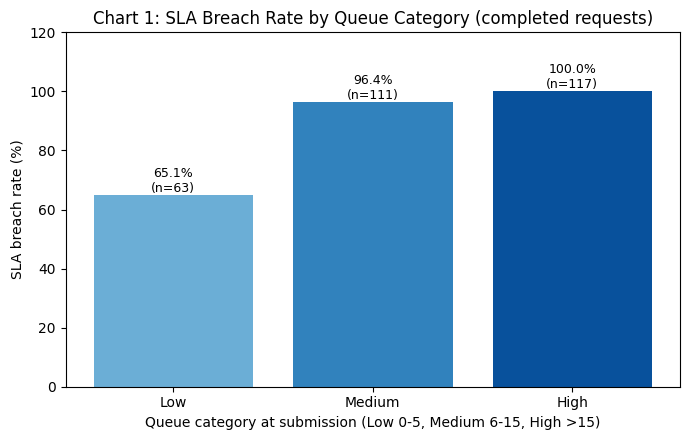


Chart 1 interpretation:
The breach rate by queue size is Low: 65.1% (n=63), Medium: 96.4% (n=111), High: 100.0% (n=117). Requests sent when the queue is long breach the target more often, so managers could add staff or send an alert when the queue goes above 15. This shows a link, not proof of cause. The smallest group has only 63 requests, so small groups can change a lot.


In [9]:
# ---------- Chart 1: breach rate by queue category ----------
fig, ax = plt.subplots(figsize=(7, 4.5))
rates = queue_stats["breach_rate"].fillna(0) * 100
bars = ax.bar(queue_stats.index.astype(str), rates, color=["#6baed6", "#3182bd", "#08519c"])
for bar, (idx, row) in zip(bars, queue_stats.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            f"{bar.get_height():.1f}%\n(n={int(row['requests'])})", ha="center", fontsize=9)
ax.set_title("Chart 1: SLA Breach Rate by Queue Category (completed requests)")
ax.set_xlabel("Queue category at submission (Low 0-5, Medium 6-15, High >15)")
ax.set_ylabel("SLA breach rate (%)")
ax.set_ylim(0, max(100, rates.max() + 20) if rates.max() > 80 else rates.max() + 20)
plt.tight_layout()
plt.savefig("chart1_queue_breach.png", dpi=150)
plt.show()

# Interpretation written by code from the real numbers
q = queue_stats.dropna(subset=["breach_rate"])
parts = ", ".join(f"{idx}: {pct(r['breach_rate'])} (n={int(r['requests'])})" for idx, r in q.iterrows())
c1_s1 = f"The breach rate by queue size is {parts}."
if {"Low", "High"}.issubset(set(q.index)):
    diff = q.loc["High", "breach_rate"] - q.loc["Low", "breach_rate"]
    if diff >= 0.05:
        c1_s2 = "Requests sent when the queue is long breach the target more often, so managers could add staff or send an alert when the queue goes above 15."
    elif diff <= -0.05:
        c1_s2 = "Long queues do not show more breaches in this data, so queue size alone does not explain the delays and managers should look for other causes."
    else:
        c1_s2 = "The breach rate is about the same for all queue sizes, so queue size alone is a weak warning signal."
else:
    c1_s2 = "Not every queue group has completed requests, so the comparison is incomplete."
c1_s3 = (f"This shows a link, not proof of cause. The smallest group has only {int(q['requests'].min())} requests, "
         f"so small groups can change a lot.")
chart1_text = " ".join([c1_s1, c1_s2, c1_s3])
print("\nChart 1 interpretation:\n" + chart1_text)

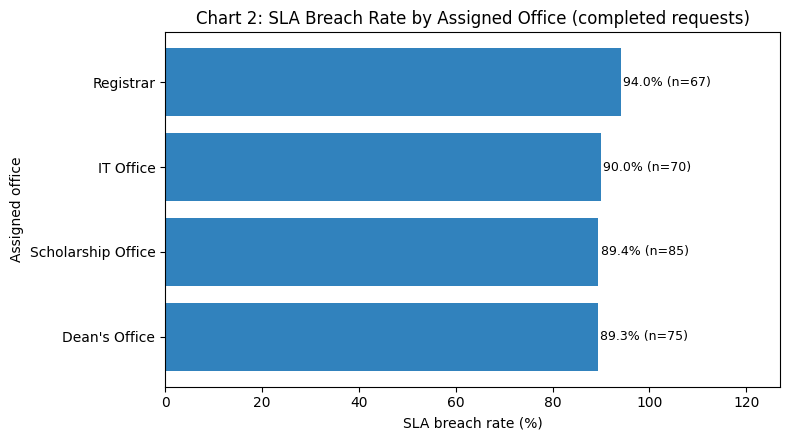


Chart 2 interpretation:
Registrar has the highest breach rate (94.0% of 67 completed requests), and Dean's Office has the lowest (89.3% of 75). The offices are close to each other (only 4.7 percentage points apart), so late requests happen in every office, not in just one. Management should look at the whole process first, and then check the highest-breach office. Every office has at least 10 completed requests, so the comparison is more reliable, but the dataset is still small.


In [10]:
# ---------- Chart 2: breach rate by office ----------
plot_df = office_stats.sort_values("breach_rate")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(plot_df.index.astype(str), plot_df["breach_rate"] * 100, color="#3182bd")
for i, (idx, row) in enumerate(plot_df.iterrows()):
    ax.text(row["breach_rate"] * 100 + 0.5, i, f"{row['breach_rate'] * 100:.1f}% (n={int(row['requests'])})",
            va="center", fontsize=9)
ax.set_title("Chart 2: SLA Breach Rate by Assigned Office (completed requests)")
ax.set_xlabel("SLA breach rate (%)")
ax.set_ylabel("Assigned office")
ax.set_xlim(0, max(plot_df["breach_rate"].max() * 100 * 1.35, 10))
plt.tight_layout()
plt.savefig("chart2_office_breach.png", dpi=150)
plt.show()

o_top, o_low = office_stats.iloc[0], office_stats.iloc[-1]
c2_s1 = (f"{office_stats.index[0]} has the highest breach rate ({pct(o_top['breach_rate'])} of {int(o_top['requests'])} completed requests), "
         f"and {office_stats.index[-1]} has the lowest ({pct(o_low['breach_rate'])} of {int(o_low['requests'])}).")
spread = o_top["breach_rate"] - o_low["breach_rate"]
if spread < 0.10:
    c2_s2 = (f"The offices are close to each other (only {spread * 100:.1f} percentage points apart), so late requests happen in every office, not in just one. "
             "Management should look at the whole process first, and then check the highest-breach office.")
else:
    c2_s2 = ("Management should first review the workload, staff and steps in the highest-breach office, "
             "and compare them with the best office to learn what it does differently.")
c2_s3 = (f"Offices with fewer than 10 completed requests ({', '.join(map(str, small_offices.index))}) are less reliable."
         if len(small_offices) else
         "Every office has at least 10 completed requests, so the comparison is more reliable, but the dataset is still small.")
chart2_text = " ".join([c2_s1, c2_s2, c2_s3])
print("\nChart 2 interpretation:\n" + chart2_text)

rep_img("chart1_queue_breach.png", "Chart 1")
rep_p("Chart 1 meaning: " + chart1_text)
rep_img("chart2_office_breach.png", "Chart 2")
rep_p("Chart 2 meaning: " + chart2_text)

---
# Part IV - Classification and Model Evaluation
## Question 8 - Decision Tree with a reproducible pipeline (80/20 split, random_state=42)
Only **submission-time** features are used. `Processing_Days`, `Status`, `Reopened` and `Satisfaction_Score` are **not** used.

In [11]:
cat_features = [c for c in ["Service_Type", "Requester_Type", "Requested_Channel", "Priority",
                            "Assigned_Office", "Required_Documents_Complete", "Submission_Weekday"]
                if c in labeled.columns]
num_features = [c for c in ["Queue_Length", "SLA_Days"] if c in labeled.columns]
features = cat_features + num_features

forbidden = {"Processing_Days", "Status", "Reopened", "Satisfaction_Score", "SLA_Breached"}
assert forbidden.isdisjoint(features), "A forbidden (after-submission) column is in the features!"
print(f"{len(features)} features used:", features)

def make_X(frame):
    # same preparation for training data and for new requests
    X = frame[features].copy()
    for c in cat_features:
        X[c] = X[c].astype(object)
    return X

X = make_X(labeled)
y = labeled["SLA_Breached"]

# 80/20 split. 'stratify' keeps the same breach share in train and test.
try:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
    split_note = "stratified"
except ValueError:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE)
    split_note = "not stratified (a class was too small)"
print(f"Train rows: {len(X_train)} | Test rows: {len(X_test)} | split: {split_note}")

preprocess = ColumnTransformer([
    ("cat", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
    ("num", SimpleImputer(strategy="median"), num_features),
])

model = Pipeline([
    ("prep", preprocess),
    ("tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)
print("Model trained. (max_depth=4 and min_samples_leaf=5 keep the tree small so it does not just memorize.)")

9 features used: ['Service_Type', 'Requester_Type', 'Requested_Channel', 'Priority', 'Assigned_Office', 'Required_Documents_Complete', 'Submission_Weekday', 'Queue_Length', 'SLA_Days']
Train rows: 237 | Test rows: 60 | split: stratified
Model trained. (max_depth=4 and min_samples_leaf=5 keep the tree small so it does not just memorize.)


## Question 9 - Evaluation: confusion matrix, metrics, baseline and top features
Positive class = 1 (SLA breached).

,Model,Accuracy,Precision (breach),Recall (breach),F1 (breach)
0,Decision Tree,0.933,0.931,1.0,0.964
1,Majority-class baseline,0.900,0.900,1.0,0.947


Confusion matrix (test set):


,Predicted 0 (on time),Predicted 1 (breached)
Actual 0 (on time),2,4
Actual 1 (breached),0,54


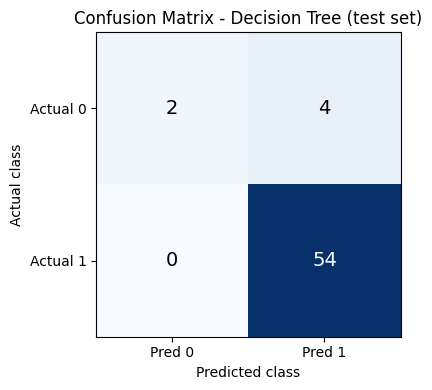

,Feature,Importance
0,Queue_Length,0.634
1,Required_Documents_Complete,0.300
2,Service_Type,0.044
3,Requester_Type,0.022
4,Requested_Channel,0.000
5,Assigned_Office,0.000
6,Priority,0.000
7,Submission_Weekday,0.000
8,SLA_Days,0.000


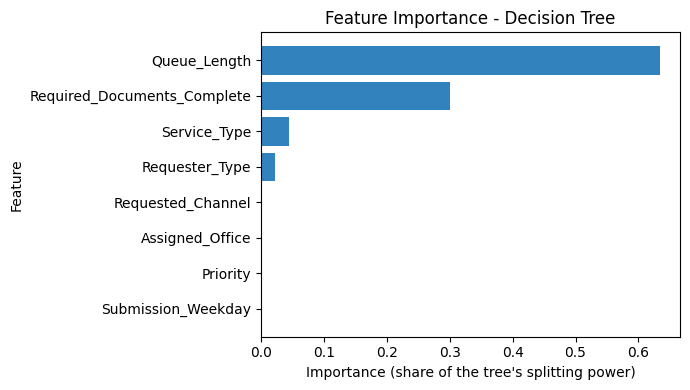

Three most influential features: Queue_Length (0.63), Required_Documents_Complete (0.30), Service_Type (0.04)

Tree rules (first levels):
|--- num__Queue_Length <= 1.50
|   |--- cat__Required_Documents_Complete_No <= 0.50
|   |   |--- num__Queue_Length <= 0.50
|   |   |   |--- class: 0
|   |   |--- num__Queue_Length >  0.50
|   |   |   |--- class: 0
|   |--- cat__Required_Documents_Complete_No >  0.50
|   |   |--- class: 1
|--- num__Queue_Length >  1.50
|   |--- num__Queue_Length <= 4.50
|   |   |--- num__Queue_Length <= 3.50
|   |   |   |--- cat__Requester_Type_Student <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- cat__Requester_Type_Student >  0.50
|   |   |   |   |--- class: 1
|   |   |--- num__Queue_Length >  3.50
|   |   |   |--- cat__Service_Type_IT Support <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- cat__Service_Type_IT Support >  0.50
|   |   |   |   |--- class: 0
|   |--- num__Queue_Length >  4.50
|   |   |--- num__Queue_Length <= 13.50
|   |   |   |--- cat

In [12]:
y_pred = model.predict(X_test)

# Majority-class baseline: always predicts the most common class of the training data
baseline = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(X_train), 1)), y_train)
y_base = baseline.predict(np.zeros((len(X_test), 1)))

def evaluate(name, y_true, y_hat):
    return {"Model": name,
            "Accuracy":           accuracy_score(y_true, y_hat),
            "Precision (breach)": precision_score(y_true, y_hat, pos_label=1, zero_division=0),
            "Recall (breach)":    recall_score(y_true, y_hat, pos_label=1, zero_division=0),
            "F1 (breach)":        f1_score(y_true, y_hat, pos_label=1, zero_division=0)}

eval_table = pd.DataFrame([evaluate("Decision Tree", y_test, y_pred),
                           evaluate("Majority-class baseline", y_test, y_base)]).round(3)
display(eval_table)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_df = pd.DataFrame(cm, index=["Actual 0 (on time)", "Actual 1 (breached)"],
                     columns=["Predicted 0 (on time)", "Predicted 1 (breached)"])
print("Confusion matrix (test set):")
display(cm_df)

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred 0", "Pred 1"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual 0", "Actual 1"])
ax.set_title("Confusion Matrix - Decision Tree (test set)")
ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

# ---- Feature importance (one-hot columns are added back to their original feature) ----
names = model.named_steps["prep"].get_feature_names_out()
importances = model.named_steps["tree"].feature_importances_
agg = {}
for name, value in zip(names, importances):
    if name.startswith("num__"):
        key = name[len("num__"):]
    else:
        rest = name[len("cat__"):]
        key = next((c for c in cat_features if rest.startswith(c + "_")), rest)
    agg[key] = agg.get(key, 0) + value
importance_df = (pd.Series(agg, name="Importance").sort_values(ascending=False)
                 .rename_axis("Feature").reset_index())
display(importance_df.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
top_plot = importance_df.head(8).iloc[::-1]
ax.barh(top_plot["Feature"], top_plot["Importance"], color="#3182bd")
ax.set_title("Feature Importance - Decision Tree")
ax.set_xlabel("Importance (share of the tree's splitting power)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

top3 = importance_df.head(3)["Feature"].tolist()
top3_text = ", ".join(f"{r['Feature']} ({r['Importance']:.2f})" for _, r in importance_df.head(3).iterrows())
print("Three most influential features:", top3_text)

print("\nTree rules (first levels):")
print(export_text(model.named_steps["tree"], feature_names=list(names), max_depth=3))

m_row = eval_table.iloc[0]; b_row = eval_table.iloc[1]
rep_h("Part IV - Classification results")
rep_p(f"A Decision Tree (max_depth=4, min_samples_leaf=5, random_state=42) was trained on {len(X_train)} requests and tested on "
      f"{len(X_test)} requests (80/20 split). Features used: {', '.join(features)}.")
rep_table(eval_table, "Evaluation table (positive class = SLA breached)")
rep_table(cm_df.reset_index().rename(columns={"index": ""}), "Confusion matrix (test set)")
rep_img("confusion_matrix.png", "Confusion matrix")
rep_img("feature_importance.png", "Feature importance")
rep_p(f"Three most influential features: {top3_text}. Importance shows how much the tree used a feature to split the data. "
      f"It does not prove that the feature causes delays.")

## Question 10 - Leakage, class imbalance and advisory use

In [13]:
breach_share = y.mean()
n_breach = int(y.sum())
majority_acc = b_row["Accuracy"]

leak_text = ("Data leakage risk: using information that is only known AFTER the request is finished. "
             "SLA_Breached is built from Processing_Days, so if Processing_Days (or Status, Reopened, Satisfaction_Score) "
             "were used as predictors, the model would already 'see the answer'. The scores would look excellent in the test "
             "but the model would fail on new requests. These four columns were removed from the features and an assert check "
             "in the code stops the notebook if one of them is added by mistake.")

if min(breach_share, 1 - breach_share) < 0.30:
    imb_state = "The classes are imbalanced."
else:
    imb_state = "The classes are fairly balanced, so this risk is smaller, but it still must be checked."
imb_text = (f"Class-imbalance risk: {imb_state} {n_breach} of {len(y)} labeled requests ({pct(breach_share)}) breached the SLA. "
            f"If one class is much bigger, a model can get a high accuracy just by always choosing the big class. "
            f"Here the majority-class baseline already gets {majority_acc:.3f} accuracy on the test set. "
            f"So accuracy alone is not enough; precision, recall and F1 for the breach class must be read as well.")

tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
on_time_total = tn + fp
on_time_text = f"The tree found {tn} of the {on_time_total} on-time requests in the test set." if on_time_total else ""
f1_gain = m_row["F1 (breach)"] - b_row["F1 (breach)"]
found_ok = (on_time_total == 0) or (tn / on_time_total >= 0.5)
if f1_gain >= 0.05 and m_row["Recall (breach)"] >= 0.5 and found_ok:
    adv_state = (f"The tree beats the baseline on F1 ({m_row['F1 (breach)']:.3f} vs {b_row['F1 (breach)']:.3f}) and finds "
                 f"{pct(m_row['Recall (breach)'])} of the breached requests in the test set, so it may be used as an ADVISORY warning only.")
elif f1_gain > 0:
    adv_state = (f"The tree is only a little better than the baseline (F1 {m_row['F1 (breach)']:.3f} vs {b_row['F1 (breach)']:.3f}). {on_time_text} "
                 f"Because most requests are breached, the model mostly answers 'breach', so it does not help much to choose which request to check first. "
                 f"It can be shown as a careful ADVISORY hint next to other information, but it is not strong enough to rely on until there is more data and a better balance of classes.")
else:
    adv_state = (f"The tree does not beat the baseline (F1 {m_row['F1 (breach)']:.3f} vs {b_row['F1 (breach)']:.3f}; "
                 f"recall {pct(m_row['Recall (breach)'])}), so it is NOT ready for real use, even as advice, until it is improved with more data.")
adv_text = (f"Suitable for advisory use? {adv_state} The test set has only {len(y_test)} requests, so the results can change a lot. "
            f"The model should only help staff decide which requests to look at first. A person must make every decision.")

for t in (leak_text, imb_text, adv_text):
    print(t, "\n")

rep_p(leak_text); rep_p(imb_text); rep_p(adv_text)

Data leakage risk: using information that is only known AFTER the request is finished. SLA_Breached is built from Processing_Days, so if Processing_Days (or Status, Reopened, Satisfaction_Score) were used as predictors, the model would already 'see the answer'. The scores would look excellent in the test but the model would fail on new requests. These four columns were removed from the features and an assert check in the code stops the notebook if one of them is added by mistake. 

Class-imbalance risk: The classes are imbalanced. 269 of 297 labeled requests (90.6%) breached the SLA. If one class is much bigger, a model can get a high accuracy just by always choosing the big class. Here the majority-class baseline already gets 0.900 accuracy on the test set. So accuracy alone is not enough; precision, recall and F1 for the breach class must be read as well. 

Suitable for advisory use? The tree is only a little better than the baseline (F1 0.964 vs 0.947). The tree found 2 of the 6 on-

---
# Part V - Requirements and UML Use Cases
## Question 11 - Three functional requirements from the real findings
The text below is built from the numbers computed above, so each requirement points to real evidence.

In [14]:
queue_valid = queue_stats.dropna(subset=["breach_rate"])
queue_evidence = ", ".join(f"{idx} = {pct(r['breach_rate'])} (n={int(r['requests'])})" for idx, r in queue_valid.iterrows())

requirements = pd.DataFrame([
    ["FR1",
     "The system shall show SLA breach rate for each assigned office, so administrators can see which offices are late.",
     f"Part III, 6b / Chart 2: highest breach rate is {top_office} at {pct(office_stats.iloc[0]['breach_rate'])} "
     f"({int(office_stats.iloc[0]['requests'])} completed requests); lowest is {office_stats.index[-1]} at {pct(office_stats.iloc[-1]['breach_rate'])}."],
    ["FR2",
     "The system shall show the number of open requests and the queue category (Low, Medium, High) of each office, and shall alert staff when a new request is submitted into a High queue (more than 15).",
     f"Part III, 6c / Chart 1: breach rate by queue category - {queue_evidence}."],
    ["FR3",
     "The system shall calculate a delay-risk flag for each new request using submission-time data only, show the main reasons, and send flagged requests to staff for human review without changing the request automatically.",
     f"Part IV: Decision Tree F1 for breach = {m_row['F1 (breach)']:.3f} vs baseline {b_row['F1 (breach)']:.3f}, recall = {m_row['Recall (breach)']:.3f}. "
     f"Most influential features: {top3_text}."],
], columns=["ID", "Functional requirement", "Evidence from the findings"])
pd.set_option("display.max_colwidth", 200)
display(requirements)

rep_h("Part V - Requirements and use cases")
rep_table(requirements, "Requirement - finding mapping")

,ID,Functional requirement,Evidence from the findings
0,FR1,"The system shall show SLA breach rate for each assigned office, so administrators can see which offices are late.","Part III, 6b / Chart 2: highest breach rate is Registrar at 94.0% (67 completed requests); lowest is Dean's Office at 89.3%."
1,FR2,"The system shall show the number of open requests and the queue category (Low, Medium, High) of each office, and shall alert staff when a new request is submitted into a High queue (more than 15).","Part III, 6c / Chart 1: breach rate by queue category - Low = 65.1% (n=63), Medium = 96.4% (n=111), High = 100.0% (n=117)."
2,FR3,"The system shall calculate a delay-risk flag for each new request using submission-time data only, show the main reasons, and send flagged requests to staff for human review without changing the r...","Part IV: Decision Tree F1 for breach = 0.964 vs baseline 0.947, recall = 1.000. Most influential features: Queue_Length (0.63), Required_Documents_Complete (0.30), Service_Type (0.04)."


## Question 12 - Updated UML Use Case Diagram
The diagram is drawn with Matplotlib and saved as a PNG file. Blue ovals are the **new analytics use cases**; grey ovals are the normal service-request use cases.

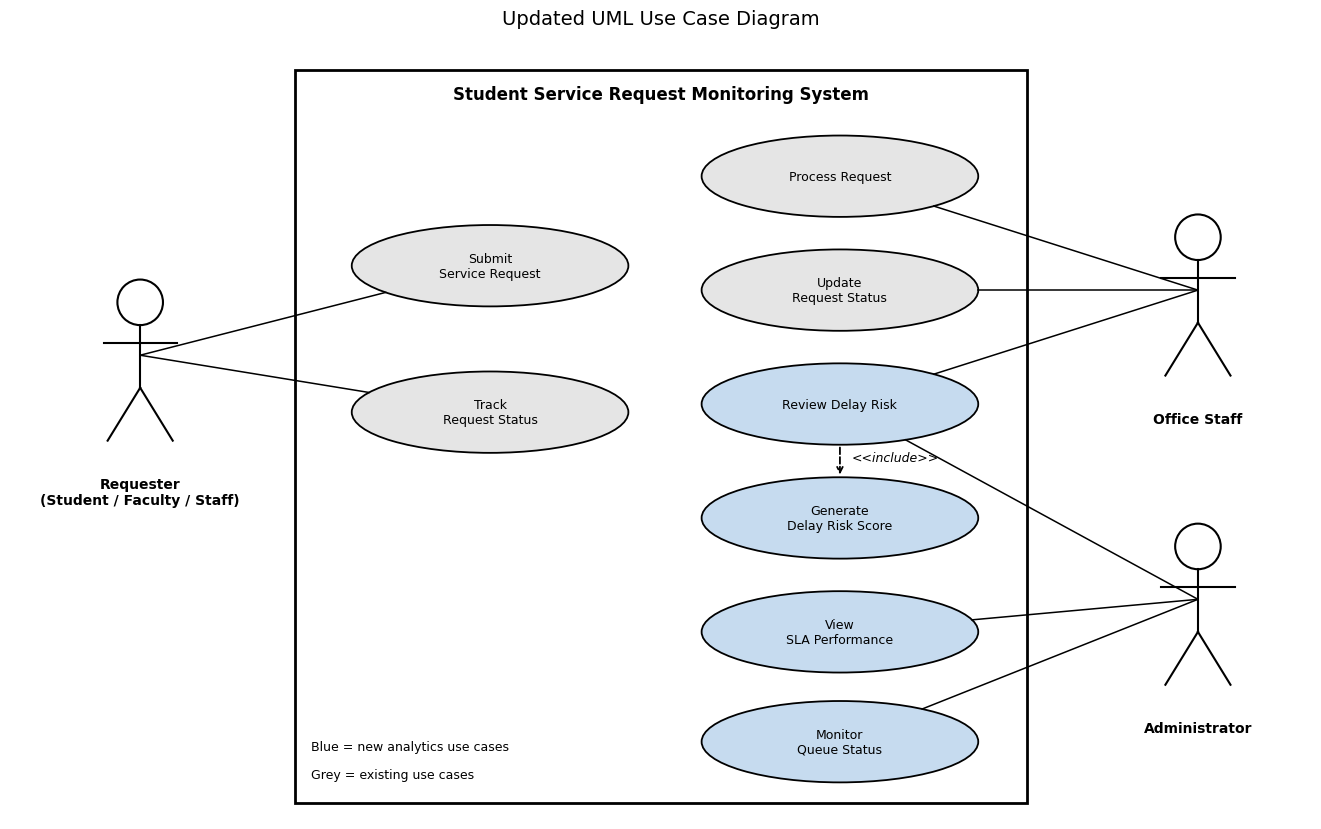

Saved UML diagram: SectionB_Baclay_ChristJohn_ExamV2_UML.png


In [15]:
from matplotlib.patches import Ellipse, Rectangle, Circle

fig, ax = plt.subplots(figsize=(14, 8.4))
ax.set_xlim(0, 16); ax.set_ylim(0, 9.6); ax.set_aspect("equal"); ax.axis("off")

# System boundary
ax.add_patch(Rectangle((3.5, 0.2), 9.0, 9.0, fill=False, linewidth=2))
ax.text(8.0, 8.85, "Student Service Request Monitoring System", ha="center", fontsize=12, fontweight="bold")

# Use cases: name -> (x, y, is_new_analytics)
A, B = 1.7, 0.5          # half width and half height of each oval
use_cases = {
    "Submit Service Request":     (5.9, 6.8, False),
    "Track Request Status":       (5.9, 5.0, False),
    "Process Request":            (10.2, 7.9, False),
    "Update Request Status":      (10.2, 6.5, False),
    "Review Delay Risk":          (10.2, 5.1, True),
    "Generate Delay Risk Score":  (10.2, 3.7, True),
    "View SLA Performance":       (10.2, 2.3, True),
    "Monitor Queue Status":       (10.2, 0.95, True),
}
for name, (x, y, new) in use_cases.items():
    ax.add_patch(Ellipse((x, y), 2 * A, 2 * B, facecolor="#c6dbef" if new else "#e5e5e5",
                         edgecolor="black", linewidth=1.3))
    ax.text(x, y, name.replace(" ", "\n", 1) if len(name) > 18 else name, ha="center", va="center", fontsize=9)

def edge_point(name, target):
    # point on the oval edge that faces the target
    cx, cy, _ = use_cases[name]
    dx, dy = target[0] - cx, target[1] - cy
    t = 1.0 / np.sqrt((dx / A) ** 2 + (dy / B) ** 2)
    return cx + t * dx, cy + t * dy

def draw_actor(x, y, label):
    ax.add_patch(Circle((x, y + 0.95), 0.28, fill=False, linewidth=1.5))
    ax.plot([x, x], [y + 0.67, y - 0.1], "k", linewidth=1.5)          # body
    ax.plot([x - 0.45, x + 0.45], [y + 0.45, y + 0.45], "k", linewidth=1.5)  # arms
    ax.plot([x, x - 0.4], [y - 0.1, y - 0.75], "k", linewidth=1.5)    # legs
    ax.plot([x, x + 0.4], [y - 0.1, y - 0.75], "k", linewidth=1.5)
    ax.text(x, y - 1.2, label, ha="center", va="top", fontsize=10, fontweight="bold")

actors = {
    "Requester":      (1.6, 5.4),
    "Office Staff":   (14.6, 6.2),
    "Administrator":  (14.6, 2.4),
}
draw_actor(1.6, 5.4, "Requester\n(Student / Faculty / Staff)")
draw_actor(14.6, 6.2, "Office Staff")
draw_actor(14.6, 2.4, "Administrator")

associations = [
    ("Requester", "Submit Service Request"), ("Requester", "Track Request Status"),
    ("Office Staff", "Process Request"), ("Office Staff", "Update Request Status"),
    ("Office Staff", "Review Delay Risk"),
    ("Administrator", "Review Delay Risk"), ("Administrator", "View SLA Performance"),
    ("Administrator", "Monitor Queue Status"),
]
for actor, uc in associations:
    ax_, ay_ = actors[actor]
    start = (ax_, ay_ + 0.3)                      # middle of the actor body
    end = edge_point(uc, start)
    ax.plot([start[0], end[0]], [start[1], end[1]], "k", linewidth=1.1)

# <<include>> : Review Delay Risk includes Generate Delay Risk Score (dashed arrow to the included use case)
ax.annotate("", xy=(10.2, 3.7 + B), xytext=(10.2, 5.1 - B),
            arrowprops=dict(arrowstyle="->", linestyle="--", linewidth=1.3))
ax.text(10.35, 4.4, "<<include>>", fontsize=9, style="italic")

ax.text(3.7, 0.85, "Blue = new analytics use cases", fontsize=9, ha="left")
ax.text(3.7, 0.5, "Grey = existing use cases", fontsize=9, ha="left")
ax.set_title("Updated UML Use Case Diagram", fontsize=14, pad=10)
plt.tight_layout()
plt.savefig(UML_PNG, dpi=170)
plt.show()
print("Saved UML diagram:", UML_PNG)

**What changed in the diagram**
- A new actor, **Administrator**, was added. Administrators use the analytics results to manage service performance.
- Three new analytics use cases were added: **View SLA Performance** (supports FR1), **Monitor Queue Status** (supports FR2) and **Review Delay Risk** (supports FR3).
- **Generate Delay Risk Score** is a separate use case that **Review Delay Risk** always uses (`<<include>>`). It is the step where the Decision Tree gives a risk value for a request.
- **Office Staff** can also use Review Delay Risk. This is the human review step: staff decide what to do with a flagged request.
- The existing use cases (Submit Service Request, Track Request Status, Process Request, Update Request Status) are kept.

In [16]:
rep_img(UML_PNG, "Updated UML Use Case Diagram")
rep_p("Changes in the diagram: a new actor (Administrator) and three new analytics use cases (View SLA Performance, "
      "Monitor Queue Status, Review Delay Risk) were added. Review Delay Risk includes Generate Delay Risk Score. "
      "Office Staff also use Review Delay Risk so that a person always reviews a flagged request. "
      "The existing use cases for requesters and office staff were kept.")

---
# Part VI - Decision Support and Critical Reflection
## Question 13 - Administrator dashboard wireframe
This sketch uses the real cleaned data. The flagged-request table scores the requests that are still **Pending** with the trained tree.

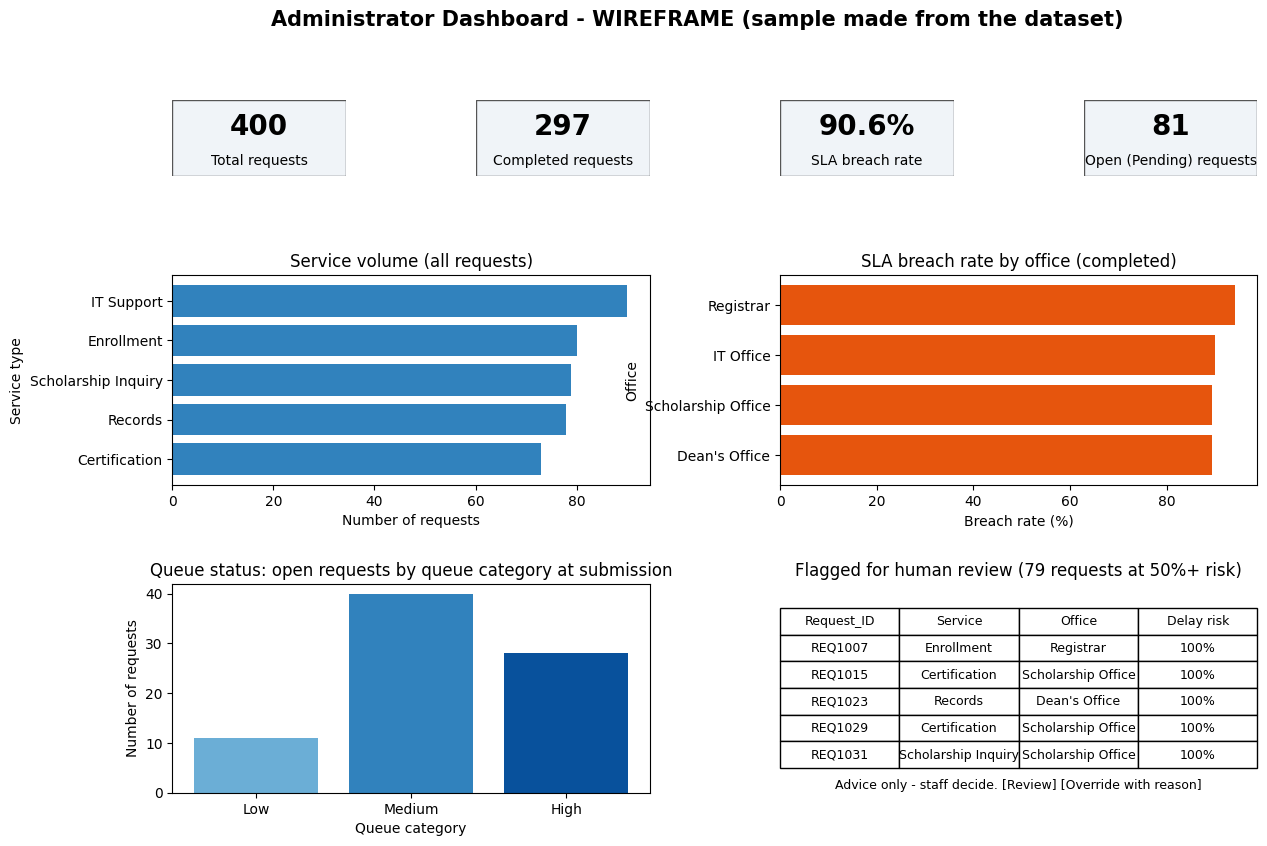

In [17]:
# ---- numbers for the dashboard ----
total_requests = len(df)
completed_n = int(is_completed.sum())
breach_rate_all = labeled["SLA_Breached"].mean()
open_reqs = df[df["Status"].astype(str).str.lower() == "pending"].copy()

# risk score for open requests (advice only)
classes = list(model.classes_)
flag_rows = []
if len(open_reqs) and 1 in classes:
    open_reqs["Risk"] = model.predict_proba(make_X(open_reqs))[:, classes.index(1)]
    flagged = open_reqs.sort_values("Risk", ascending=False)
    n_flagged = int((flagged["Risk"] >= 0.5).sum())
    for _, r in flagged.head(5).iterrows():
        flag_rows.append([str(r["Request_ID"]), str(r["Service_Type"]), str(r["Assigned_Office"]), f"{r['Risk'] * 100:.0f}%"])
else:
    n_flagged = 0

fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(3, 4, height_ratios=[0.55, 1.5, 1.5], hspace=0.6, wspace=0.75)
fig.suptitle("Administrator Dashboard - WIREFRAME (sample made from the dataset)", fontsize=15, fontweight="bold")

kpis = [("Total requests", f"{total_requests}"),
        ("Completed requests", f"{completed_n}"),
        ("SLA breach rate", pct(breach_rate_all)),
        ("Open (Pending) requests", f"{len(open_reqs)}")]
for i, (title, value) in enumerate(kpis):
    a = fig.add_subplot(gs[0, i]); a.axis("off")
    a.add_patch(Rectangle((0, 0), 1, 1, facecolor="#f0f4f8", edgecolor="#555", transform=a.transAxes))
    a.text(0.5, 0.65, value, ha="center", va="center", fontsize=20, fontweight="bold", transform=a.transAxes)
    a.text(0.5, 0.2, title, ha="center", va="center", fontsize=10, transform=a.transAxes)

# Service volume
a = fig.add_subplot(gs[1, 0:2])
sv = service_counts.sort_values()
a.barh(sv.index.astype(str), sv.values, color="#3182bd")
a.set_title("Service volume (all requests)"); a.set_xlabel("Number of requests"); a.set_ylabel("Service type")

# SLA breach rate by office
a = fig.add_subplot(gs[1, 2:4])
ob = office_stats.sort_values("breach_rate")
a.barh(ob.index.astype(str), ob["breach_rate"] * 100, color="#e6550d")
a.set_title("SLA breach rate by office (completed)"); a.set_xlabel("Breach rate (%)"); a.set_ylabel("Office")

# Queue status
a = fig.add_subplot(gs[2, 0:2])
if len(open_reqs):
    qs = open_reqs["Queue_Category"].value_counts().reindex(["Low", "Medium", "High"]).fillna(0)
    a.bar(qs.index.astype(str), qs.values, color=["#6baed6", "#3182bd", "#08519c"])
    a.set_title("Queue status: open requests by queue category at submission")
else:
    qs = df["Queue_Category"].value_counts().reindex(["Low", "Medium", "High"]).fillna(0)
    a.bar(qs.index.astype(str), qs.values, color=["#6baed6", "#3182bd", "#08519c"])
    a.set_title("Queue status: all requests by queue category (no pending requests found)")
a.set_xlabel("Queue category"); a.set_ylabel("Number of requests")

# Flagged requests
a = fig.add_subplot(gs[2, 2:4]); a.axis("off")
a.set_title(f"Flagged for human review ({n_flagged} requests at 50%+ risk)")
if flag_rows:
    tbl = a.table(cellText=flag_rows, colLabels=["Request_ID", "Service", "Office", "Delay risk"],
                  loc="center", cellLoc="center")
    tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.6)
    a.text(0.5, 0.02, "Advice only - staff decide. [Review] [Override with reason]", ha="center",
           fontsize=9, transform=a.transAxes)
else:
    a.text(0.5, 0.5, "No pending requests to score in this dataset.", ha="center", va="center", transform=a.transAxes)

plt.savefig("dashboard_wireframe.png", dpi=150, bbox_inches="tight")
plt.show()

rep_h("Part VI - Decision support")
rep_img("dashboard_wireframe.png", "Administrator dashboard wireframe")
rep_p("Dashboard: four number tiles (total requests, completed requests, SLA breach rate, open requests), a service-volume chart, "
      "a breach-rate-by-office chart, a queue-status chart, and a table of flagged requests that goes to human review.")

## Question 14 - Human review, missing data and explanations

In [18]:
missing_pred = labeled[features].isna().sum()
missing_pred = missing_pred[missing_pred > 0]
if len(missing_pred):
    miss_text = ", ".join(f"{c}: {int(n)}" for c, n in missing_pred.items())
    miss_state = (f"In the labeled data, these predictor columns have missing values: {miss_text}. "
                  f"The pipeline fills them with the median (numbers) or the most common value (text). These are guesses.")
else:
    miss_state = "The labeled data has no missing predictor values now, but new requests in real use may have some."

a14_1 = ("Why human review and not automatic denial: the model only finds patterns from past requests and it can be wrong "
         f"(see precision {m_row['Precision (breach)']:.3f} and recall {m_row['Recall (breach)']:.3f}). "
         "It does not know special cases, such as an urgent need of a student. An automatic denial could hurt a real person "
         "without a chance to explain. A staff member can check the case, talk to the requester, and decide. "
         "A high-risk flag should help staff choose what to look at first. It should not decide.")
a14_2 = ("How missing data affects reliability: " + miss_state + " When many values are missing, the risk score is less reliable, "
         "so the system should show a data-completeness warning next to the score and should not rely on the flag when key fields are empty.")
a14_3 = ("What to show to explain a prediction: (1) the risk level and percent; (2) the top reasons, for example queue length, SLA days, "
         "assigned office and whether documents are complete; (3) the breach rate of similar past requests; "
         "(4) a warning about missing data; (5) a short note that the score is advice only, with the model's accuracy and recall; "
         "(6) buttons for staff to confirm or override the flag and write a reason.")
for t in (a14_1, a14_2, a14_3):
    print(t, "\n")

rep_p("14a. " + a14_1); rep_p("14b. " + a14_2); rep_p("14c. " + a14_3)

Why human review and not automatic denial: the model only finds patterns from past requests and it can be wrong (see precision 0.931 and recall 1.000). It does not know special cases, such as an urgent need of a student. An automatic denial could hurt a real person without a chance to explain. A staff member can check the case, talk to the requester, and decide. A high-risk flag should help staff choose what to look at first. It should not decide. 

How missing data affects reliability: In the labeled data, these predictor columns have missing values: Queue_Length: 6. The pipeline fills them with the median (numbers) or the most common value (text). These are guesses. When many values are missing, the risk score is less reliable, so the system should show a data-completeness warning next to the score and should not rely on the flag when key fields are empty. 

What to show to explain a prediction: (1) the risk level and percent; (2) the top reasons, for example queue length, SLA days, 